# Семинар 2. Нормализующие потоки и диффузионные модели

**Газпром · 90 минут · практикум с готовым кодом**

- **Подготовка:** Python, основы нейросетей.
- **Вопрос занятия:** как вычислять плотность данных и как превратить удаление шума в управляемую генерацию и редактирование?
- **Цель:** оценивание плотности, генерация и редактирование изображений.
- **Данные:** двумерные точки; рукописные цифры 28×28 MNIST.
- **Формат:** выполнение ячеек, анализ графиков, изменение параметров.
- **Запуск:** загрузить notebook в [Colab](https://colab.research.google.com/) → «Выполнить все». Для обучения свёрточных сетей рекомендуется GPU; CPU поддерживается. MNIST загружается один раз (~12 MB).
- **Область применимости:** учебные эксперименты; эффективность на производственных данных не оценивается.

| Минуты | Основной материал |
|---|---|
| 0–5 | Стартовый резерв: Colab и «Выполнить все» в фоне |
| 5–11 | Задача плотности и гауссовская модель |
| 11–28 | RealNVP: замена переменных, генерация, обратимость |
| 28–33 | Условный поток и ограничения обратимой архитектуры |
| 33–55 | DDPM: зашумление, предсказание шума, обратная цепочка |
| 55–70 | Один опыт: SDEdit; возможна замена на CFG |
| 70–73 | Краткая демонстрация второго механизма |
| 73–80 | Сравнение четырёх семейств |
| 80–90 | Резерв на вопросы и задержки |

Дополнительно: число слоёв потока, якобиан, коэффициенты posterior, inpainting.
**Проведение:** 75 минут основного материала + 15 минут резерва (5 минут старта и 10 минут в конце). Один самостоятельный опыт. «Выполнить все» заранее выполняет также дополнительные зависимости; на занятии их код не разбирается.
- Если подключение задержалось более чем на 5 минут, продолжить по сохранённым outputs. Повторять только короткие ячейки генерации/редактирования; обучение и дополнительные опыты оставить после занятия.

**Сохранённые результаты:** примеры без повторного запуска относятся к проверенной версии v1.2.0. Изменённые кодовые ячейки оставлены без старых outputs; новый полный прогон этой редакции пока не выполнялся.

## 0. Среда и воспроизводимость

- Фиксированы seed и два CPU-потока; версии выводятся ниже.
- Побитовое совпадение разных GPU и версий не гарантируется.
- Отсутствующие библиотеки устанавливаются автоматически.
- `QUICK_MODE` в первой кодовой ячейке включает короткую проверку исполнения; для полноценной генерации оставьте его выключенным. После смены режима заново выполнить первую ячейку, данные и обучение.
- [Заметки преподавателя по каждому разделу](https://github.com/fpakhurov/gazprom-generative-seminars/blob/main/LECTURER_NOTES_02.md).

In [ ]:
#@title Setup: device and quick smoke mode
import importlib.util
import os
import subprocess
import sys

packages = {"torch": "torch", "numpy": "numpy", "matplotlib": "matplotlib", "sklearn": "scikit-learn"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import math
import random
import time
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK_MODE = False #@param {type:"boolean"}
QUICK = QUICK_MODE or os.environ.get("SEMINAR_QUICK", "0") == "1"
plt.rcParams.update({"figure.figsize": (9, 3), "font.size": 11, "figure.dpi": 140, "axes.spines.top": False, "axes.spines.right": False})
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__, "NumPy:", np.__version__, "scikit-learn:", sklearn.__version__)
print("Device:", device, "Quick smoke mode:", QUICK)

## 1. Оценивание двумерного распределения

- **Данные:** точки $x=(x_1,x_2)$; две зашумлённые полуокружности.
- **Базовая модель:** нормальное распределение с полной ковариационной матрицей.
- **Разбиение:** train/test до стандартизации; параметры стандартизации вычисляются по train.
- **Критерий:** отрицательное логарифмическое правдоподобие (NLL) на test.

Теория: [Генеративное моделирование](https://fpakhurov.com/ru/notes/generative-models/generative-modeling/).

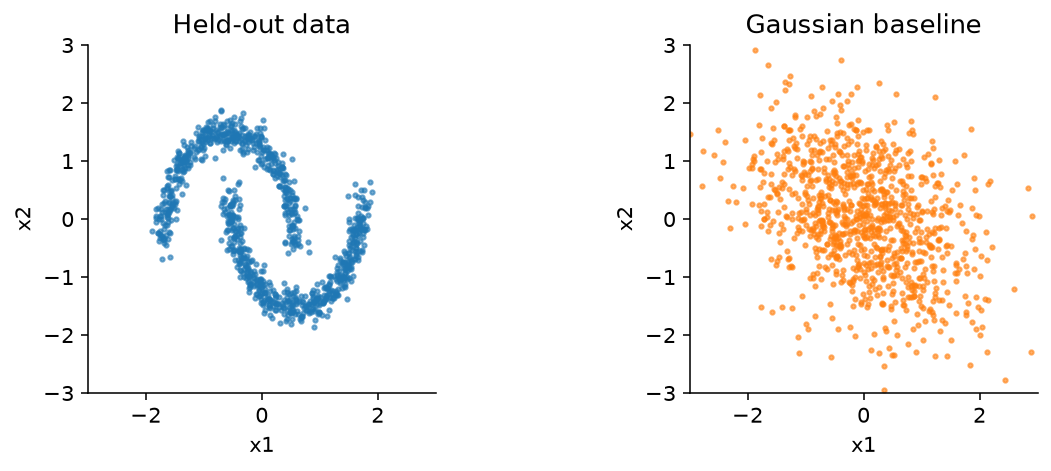

Gaussian held-out NLL: 2.7190 nats per 2D point


In [2]:
moons, moon_labels = make_moons(n_samples=5000, noise=0.07, random_state=SEED)
moon_train_np, moon_test_np, moon_train_y, moon_test_y = train_test_split(moons, moon_labels, test_size=0.2, random_state=SEED)
moon_mean = moon_train_np.mean(axis=0)
moon_scale = moon_train_np.std(axis=0)
moon_train = torch.tensor((moon_train_np - moon_mean) / moon_scale, dtype=torch.float32, device=device)
moon_test = torch.tensor((moon_test_np - moon_mean) / moon_scale, dtype=torch.float32, device=device)
gaussian_mean = moon_train.mean(dim=0)
centered = moon_train - gaussian_mean
gaussian_cov = centered.T @ centered / len(moon_train) + 1e-5 * torch.eye(2, device=device)
gaussian = torch.distributions.MultivariateNormal(gaussian_mean, covariance_matrix=gaussian_cov)
gaussian_nll = -gaussian.log_prob(moon_test).mean().item()
gaussian_samples = gaussian.sample((1000,)).cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].scatter(*moon_test.cpu().numpy().T, s=5, alpha=0.6)
axes[1].scatter(*gaussian_samples.T, s=5, alpha=0.6, color="tab:orange")
for ax, title in zip(axes, ["Held-out data", "Gaussian baseline"]):
    ax.set(title=title, xlim=(-3, 3), ylim=(-3, 3), aspect="equal", xlabel="x1", ylabel="x2")
plt.tight_layout()
plt.show()
print(f"Gaussian held-out NLL: {gaussian_nll:.4f} nats per 2D point")

- **Ограничение базовой модели:** одна нормаль не воспроизводит изогнутую форму распределения.
- **Нормализующий поток:** обратимое преобразование $z=f_\theta(x)$ к $\mathcal N(0,I)$.
- **Генерация:** $z\sim\mathcal N(0,I)$, затем $x=f_\theta^{-1}(z)$.
- **Размерность:** $x,z\in\mathbb R^2$; сжатия размерности нет.

Теория: [Нормализующие потоки](https://fpakhurov.com/ru/notes/generative-models/normalizing-flows/).

## 2. Замена переменных и архитектура RealNVP

<img src="https://lilianweng.github.io/posts/2018-10-13-flow-models/normalizing-flow.png" alt="Normalizing flow: composition of invertible transformations" width="720">

*Композиция обратимых преобразований. [Lilian Weng (2018)](https://lilianweng.github.io/posts/2018-10-13-flow-models/). На схеме: шум → данные; в коде `forward`: данные → код.*

**Плотность; направление данные → код:**

$$\log p_\theta(x)=\log p_Z(f_\theta(x))+
\log\left|\det\frac{\partial f_\theta(x)}{\partial x}\right|.$$

- $p_Z$ — стандартная нормальная плотность; $\theta$ — параметры сети.
- $|\det J_f|$ — локальное изменение объёма; `logdet` — его логарифм.
- **Цель:** $\displaystyle\min_\theta-\frac1N\sum_{i=1}^N\log p_\theta(x_i)$; $N$ — число объектов.
- NLL измеряется в натах на двумерную точку. Непрерывная плотность может превышать 1; NLL может быть отрицательной.

**Affine coupling:**

$$z_1=x_1,\qquad z_2=x_2e^{s_\theta(x_1)}+b_\theta(x_1).$$
$$x_1=z_1,\qquad x_2=(z_2-b_\theta(z_1))e^{-s_\theta(z_1)}.$$

- $s_\theta,b_\theta$ — нейросети масштаба и сдвига; их обратимость не требуется.
- Якобиан треугольный: $\log|\det J|=s_\theta(x_1)$.
- Чередование масок изменяет обе координаты; `mask=1` сохраняет координату.

Теория: [Замена переменных](https://fpakhurov.com/ru/notes/generative-models/normalizing-flows/#change-of-variables), [coupling NICE/RealNVP](https://fpakhurov.com/ru/notes/generative-models/flow-architectures/#a-coupling-layers-nice-realnvp).

In [3]:
class AffineCoupling(nn.Module):
    def __init__(self, mask, width=64):
        super().__init__()
        self.register_buffer("mask", torch.tensor(mask, dtype=torch.float32))
        self.net = nn.Sequential(nn.Linear(2, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(), nn.Linear(width, 4))
        nn.init.zeros_(self.net[-1].weight)
        nn.init.zeros_(self.net[-1].bias)

    def scale_shift(self, fixed):
        raw_scale, shift = self.net(fixed).chunk(2, dim=-1)
        scale = 0.8 * torch.tanh(raw_scale) * (1 - self.mask)
        shift = shift * (1 - self.mask)
        return scale, shift

    def forward(self, x):
        fixed = x * self.mask
        scale, shift = self.scale_shift(fixed)
        z = fixed + (1 - self.mask) * (x * scale.exp() + shift)
        return z, scale.sum(dim=-1)

    def inverse(self, z):
        fixed = z * self.mask
        scale, shift = self.scale_shift(fixed)
        x = fixed + (1 - self.mask) * ((z - shift) * (-scale).exp())
        return x, -scale.sum(dim=-1)


class RealNVP(nn.Module):
    def __init__(self, n_layers=8):
        super().__init__()
        self.layers = nn.ModuleList([AffineCoupling([i % 2, 1 - i % 2]) for i in range(n_layers)])

    def forward(self, x):
        logdet = x.new_zeros(len(x))
        for layer in self.layers:
            x, increment = layer(x)
            logdet = logdet + increment
        return x, logdet

    def inverse(self, z, return_stages=False):
        stages = [z.detach().cpu().numpy()]
        logdet = z.new_zeros(len(z))
        for layer in reversed(self.layers):
            z, increment = layer.inverse(z)
            logdet = logdet + increment
            if return_stages:
                stages.append(z.detach().cpu().numpy())
        return (z, logdet, stages) if return_stages else (z, logdet)

    def log_prob(self, x):
        z, logdet = self(x)
        log_base = -0.5 * (z.square() + math.log(2 * math.pi)).sum(dim=-1)
        return log_base + logdet


flow = RealNVP(n_layers=8).to(device)
print("Input: [batch, 2]; code: [batch, 2]; logdet: [batch]")

Input: [batch, 2]; code: [batch, 2]; logdet: [batch]


## 3. Обучение и проверка потока

- **Оптимизация:** случайные train-батчи; минимизация NLL.
- **Оценивание:** test NLL относительно гауссовской модели; test исключён из градиентов.
- **Как читать три панели:** слева train NLL по шагам оптимизации; в центре реальные test-точки после преобразования x→z; справа новые точки z→x из нормального распределения.
- **Метрика сравнения:** напечатанный test NLL, меньше — лучше в одной системе координат. Это плотность непрерывных данных: NLL может быть отрицательным; это не accuracy.

In [ ]:
FLOW_STEPS = 120 if QUICK else 1600
flow_optimizer = torch.optim.Adam(flow.parameters(), lr=1e-3)
flow_history = []
print(f"Flow mode: {'quick' if QUICK else 'full'}; device: {device}; steps: {FLOW_STEPS}", flush=True)
flow_start = time.perf_counter()
for step in range(FLOW_STEPS):
    indices = torch.randint(len(moon_train), (256,), device=device)
    flow_loss = -flow.log_prob(moon_train[indices]).mean()
    flow_optimizer.zero_grad(set_to_none=True)
    flow_loss.backward()
    torch.nn.utils.clip_grad_norm_(flow.parameters(), 5.0)
    flow_optimizer.step()
    if step % 40 == 0:
        flow_history.append((step, flow_loss.item()))
flow.eval()
with torch.no_grad():
    flow_nll = -flow.log_prob(moon_test).mean().item()
    latent_test, _ = flow(moon_test)
    base = torch.randn(1200, 2, device=device)
    flow_samples, _, flow_stages = flow.inverse(base, return_stages=True)
flow_seconds = time.perf_counter() - flow_start
print(f"Flow training and evaluation: {flow_seconds:.1f} seconds")
print(f"Held-out NLL, Gaussian: {gaussian_nll:.4f}; flow: {flow_nll:.4f} nats per 2D point")
print("Flow NLL improvement:", round(gaussian_nll - flow_nll, 4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
axes[0].plot(*np.array(flow_history).T)
axes[0].set(title="Flow training", xlabel="Step", ylabel="Train NLL")
axes[1].scatter(*latent_test.cpu().numpy().T, s=4, alpha=0.5)
axes[1].set(title="Test data transformed to z", xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
axes[2].scatter(*flow_samples.cpu().numpy().T, s=4, alpha=0.5, color="tab:orange")
axes[2].set(title="Generated points", xlim=(-3, 3), ylim=(-3, 3), aspect="equal")
plt.tight_layout()
plt.show()

- **Обратимость:** проверка `inverse(forward(x)) ≈ x`.
- **Дополнительно:** сравнение аналитического logdet с полным якобианом autograd.
- **Визуализация:** одинаковый цвет соответствует одним точкам на последовательных стадиях преобразования. Это слои одной уже обученной модели, а не эпохи обучения.
- Roundtrip/logdet errors проверяют реализацию обратимости; они не измеряют правдоподобие новых сэмплов.

Roundtrip max error: 7.15e-07


Forward/inverse logdet cancellation: 4.77e-07
Autograd/analytic logdet error: 1.67e-06


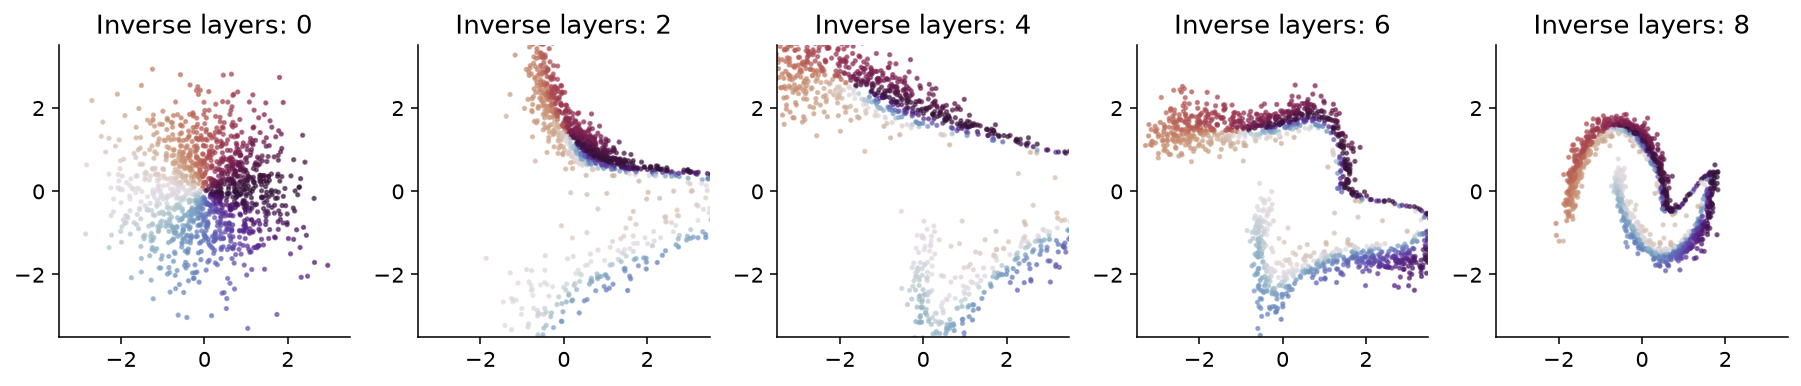

In [5]:
with torch.no_grad():
    probe = moon_test[:32]
    probe_z, forward_logdet = flow(probe)
    recovered, inverse_logdet = flow.inverse(probe_z)
    roundtrip_error = (recovered - probe).abs().max().item()
    logdet_cancellation = (forward_logdet + inverse_logdet).abs().max().item()
assert roundtrip_error < 2e-4, roundtrip_error
assert logdet_cancellation < 2e-4, logdet_cancellation

point = moon_test[0].detach().clone().requires_grad_(True)
jacobian = torch.autograd.functional.jacobian(lambda v: flow(v.unsqueeze(0))[0].squeeze(0), point)
autograd_logdet = torch.linalg.slogdet(jacobian)[1]
analytic_logdet = flow(point.unsqueeze(0))[1][0]
jacobian_logdet_error = (autograd_logdet - analytic_logdet).abs().item()
assert jacobian_logdet_error < 2e-4, jacobian_logdet_error
print(f"Roundtrip max error: {roundtrip_error:.2e}")
print(f"Forward/inverse logdet cancellation: {logdet_cancellation:.2e}")
print(f"Autograd/analytic logdet error: {jacobian_logdet_error:.2e}")

fig, axes = plt.subplots(1, 5, figsize=(13, 3))
colors = np.arctan2(flow_stages[0][:, 1], flow_stages[0][:, 0])
for ax, stage in zip(axes, [0, 2, 4, 6, 8]):
    ax.scatter(*flow_stages[stage].T, c=colors, cmap="twilight", s=3, alpha=0.6)
    ax.set(title=f"Inverse layers: {stage}", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5), aspect="equal")
plt.tight_layout()
plt.show()

### Условный поток: отдельное распределение для каждого класса

- Условие $y$ выбирает один из двух обучаемых потоков: $p(x\mid y)$.
- Одинаковые базовые точки $z$ преобразуются в разные классы.
- Сравнивать с безусловной моделью следует маргинальную плотность $p(x)=\sum_y p(y)p(x\mid y)$, а не $p(x\mid y)$.
- Это простая реализация условия через выбор параметров; общая сеть с embedding является альтернативой.

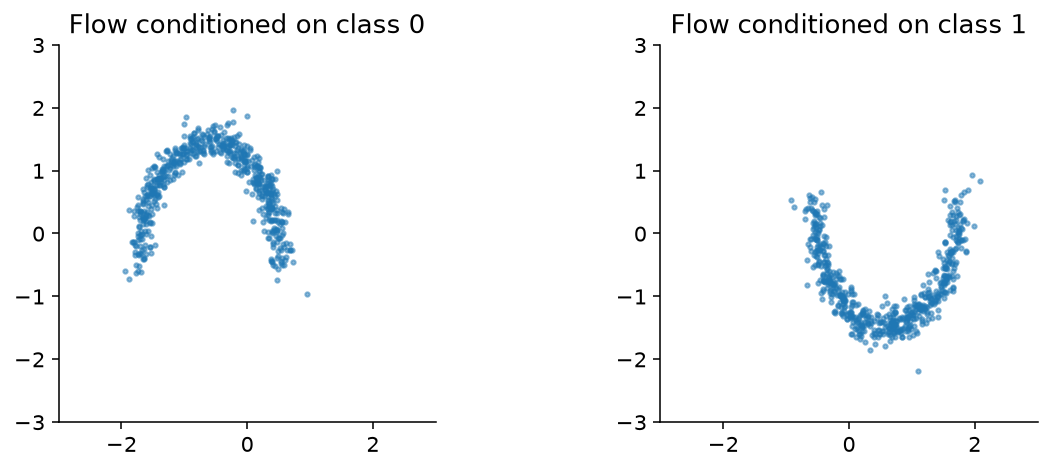

Conditional-flow mixture held-out marginal NLL: 1.5373


In [6]:
class_flows = nn.ModuleList([RealNVP(n_layers=4), RealNVP(n_layers=4)]).to(device)
class_optimizer = torch.optim.Adam(class_flows.parameters(), lr=1e-3)
train_class = torch.tensor(moon_train_y, dtype=torch.long, device=device)
class_steps = 60 if QUICK else 1000
for step in range(class_steps):
    loss = 0.0
    for label in range(2):
        group = moon_train[train_class == label]
        chosen = group[torch.randint(len(group), (128,), device=device)]
        loss = loss - class_flows[label].log_prob(chosen).mean()
    class_optimizer.zero_grad(set_to_none=True)
    loss.backward(); class_optimizer.step()
with torch.no_grad():
    fixed_base = torch.randn(600, 2, device=device)
    class_samples = [model.inverse(fixed_base)[0].cpu().numpy() for model in class_flows]
    class_prior = torch.bincount(train_class, minlength=2).float() / len(train_class)
    log_marginal = torch.logsumexp(torch.stack([model.log_prob(moon_test) + class_prior[label].log() for label, model in enumerate(class_flows)], dim=1), dim=1)
    conditional_flow_marginal_nll = -log_marginal.mean().item()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for label, axis in enumerate(axes):
    axis.scatter(*class_samples[label].T, s=5, alpha=0.5)
    axis.set(title=f"Flow conditioned on class {label}", xlim=(-3,3), ylim=(-3,3), aspect="equal")
plt.tight_layout(); plt.show()
print(f"Conditional-flow mixture held-out marginal NLL: {conditional_flow_marginal_nll:.4f}")

- **Ограничения:** специальная обратимая архитектура; положительная плотность при нормальном prior. Данные имеют ненулевой шум.
- **Дополнительный эксперимент:** 8 → 2 слоя; сравнить test NLL и генерацию. Для графика стадий задать `[0, 1, 2]` и три оси.

<details><summary>Пояснение</summary>

Один coupling-слой сохраняет часть координат. Чередование масок обеспечивает преобразование обеих. Дополнительные слои повышают выразительность, но не гарантируют улучшение test NLL.
</details>

Теория: [Архитектуры потоков](https://fpakhurov.com/ru/notes/generative-models/flow-architectures/).

## 4. DDPM: прямой процесс

Поток вычисляет плотность благодаря специальной обратимой архитектуре. Диффузионный подход использует другой компромисс: обучение удалению известного шума и многошаговую генерацию. Теперь перейдём от двумерных точек к цифрам 28×28; сеть обратного процесса будет свёрточной.

<img src="https://hojonathanho.github.io/diffusion/assets/img/pgm_diagram_xarrow.png" alt="DDPM: forward noising and learned reverse Markov chains" width="720">

*Прямой и обратный процессы DDPM. [Ho, Jain, Abbeel (2020)](https://hojonathanho.github.io/diffusion/).*

- **Данные:** $x_0\in[-1,1]^{784}$ — развёрнутое изображение 28×28.
- **Переход:** $q(x_k\mid x_{k-1})=\mathcal N(\sqrt{\alpha_k}x_{k-1},\beta_k I)$.
- $k=1,\ldots,T$ — шаг; $\beta_k$ — дисперсия шума; $\alpha_k=1-\beta_k$.
- $\bar\alpha_k=\prod_{j=1}^k\alpha_j$, $\bar\alpha_0=1$.

**Прямое получение зашумлённого примера:**

$$x_k=\sqrt{\bar\alpha_k}x_0+\sqrt{1-\bar\alpha_k}\,\varepsilon,
\qquad\varepsilon\sim\mathcal N(0,I).$$

- Чистый объект и добавленный шум известны при обучении.
- **Индексы Python:** `t=k-1`; `q_sample(x0, t=0)` соответствует первому зашумлению.

Теория: [Прямой переход к произвольному шагу](https://fpakhurov.com/ru/notes/generative-models/ddpm-forward-process/#the-jump-from-x-to-any-step).

Diffusion training device: mps


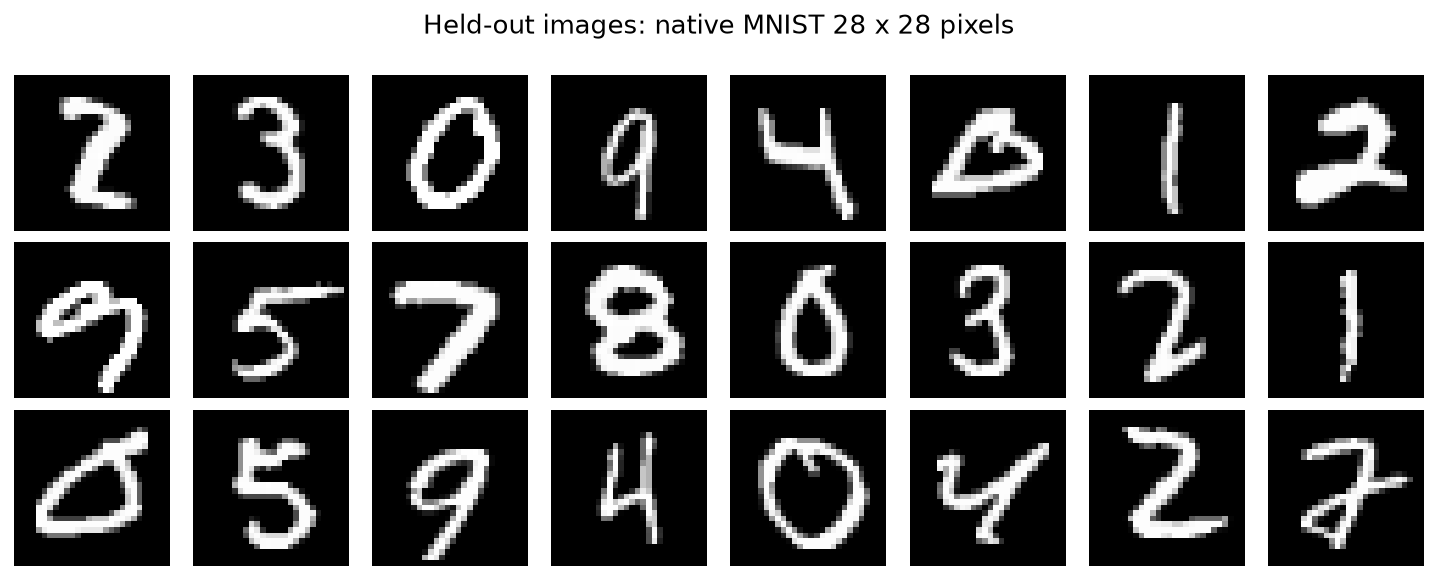

Train: (12000, 784) Test: (2000, 784)


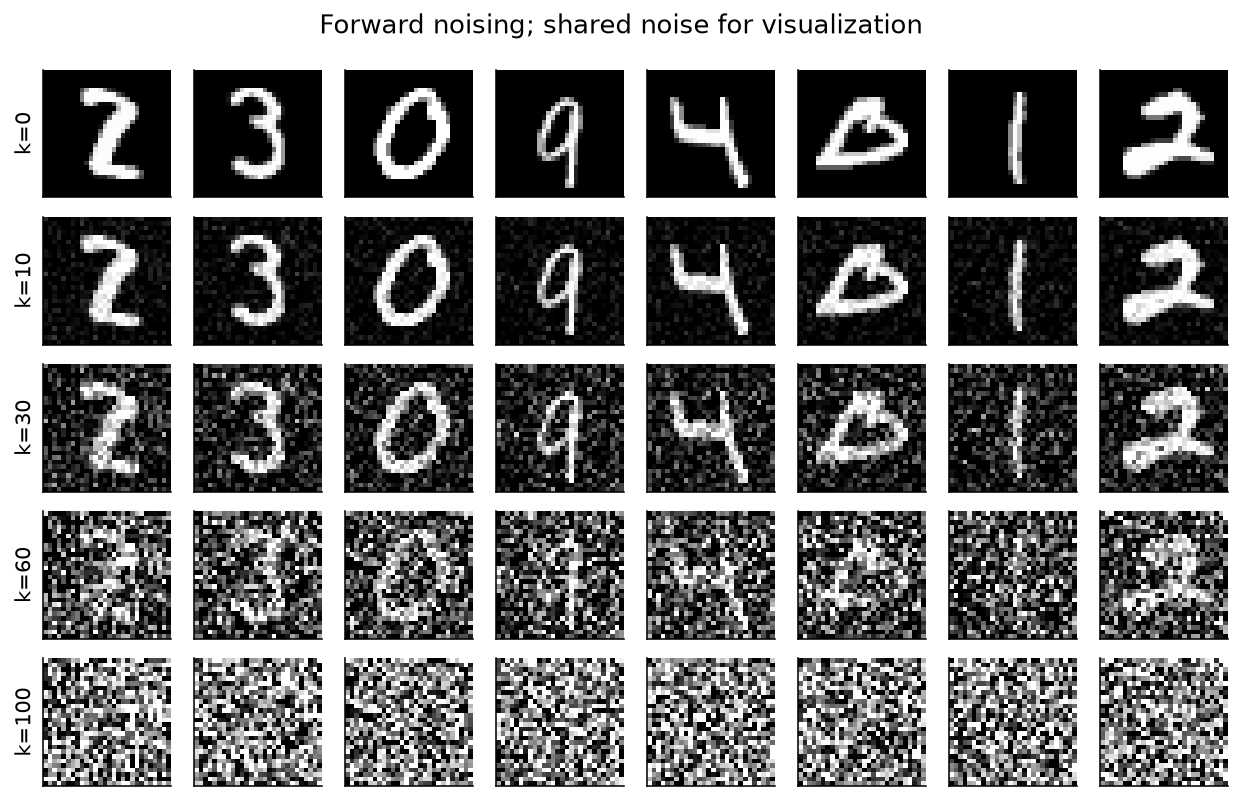

Terminal alpha_bar: 2.43e-07


In [7]:
"""Load native-resolution MNIST with a small verified download cache."""

from pathlib import Path
import gzip
import hashlib
import struct
import urllib.request

import numpy as np
from sklearn.model_selection import train_test_split

MNIST_FILES = {
    "train-images-idx3-ubyte.gz": "f68b3c2dcbeaaa9fbdd348bbdeb94873",
    "train-labels-idx1-ubyte.gz": "d53e105ee54ea40749a09fcbcd1e9432",
    "t10k-images-idx3-ubyte.gz": "9fb629c4189551a2d022fa330f9573f3",
    "t10k-labels-idx1-ubyte.gz": "ec29112dd5afa0611ce80d1b7f02629c",
}


def load_mnist(cache="data/mnist", train_limit=12000, test_limit=2000, seed=42):
    cache = Path(cache)
    cache.mkdir(parents=True, exist_ok=True)
    arrays = {}
    for filename, expected in MNIST_FILES.items():
        path = cache / filename
        if not path.exists():
            url = "https://storage.googleapis.com/cvdf-datasets/mnist/" + filename
            with urllib.request.urlopen(url, timeout=90) as response:
                path.write_bytes(response.read())
        if hashlib.md5(path.read_bytes()).hexdigest() != expected:
            raise ValueError(f"MNIST checksum mismatch: {filename}; remove the cached file and rerun")
        payload = gzip.decompress(path.read_bytes())
        magic, count = struct.unpack(">II", payload[:8])
        if magic == 2051:
            rows, cols = struct.unpack(">II", payload[8:16])
            assert (rows, cols) == (28, 28)
            values = np.frombuffer(payload, dtype=np.uint8, offset=16).reshape(count, rows, cols)
        elif magic == 2049:
            values = np.frombuffer(payload, dtype=np.uint8, offset=8)
            assert len(values) == count
        else:
            raise ValueError(f"Unexpected MNIST magic: {magic}")
        arrays[filename] = values

    def subset(images, labels, limit):
        assert len(images) == len(labels)
        indices, _ = train_test_split(np.arange(len(labels)), train_size=limit,
                                      stratify=labels, random_state=seed)
        return images[indices].astype("float32").reshape(-1, 784) / 255.0, labels[indices].astype("int64")

    train_x, train_y = subset(arrays["train-images-idx3-ubyte.gz"], arrays["train-labels-idx1-ubyte.gz"], train_limit)
    test_x, test_y = subset(arrays["t10k-images-idx3-ubyte.gz"], arrays["t10k-labels-idx1-ubyte.gz"], test_limit)
    return train_x, test_x, train_y, test_y

requested_device = os.environ.get("SEMINAR_DIFFUSION_DEVICE")
if requested_device:
    device = torch.device(requested_device)
print("Diffusion training device:", device)
IMAGE_SIZE = 28
INPUT_DIM = IMAGE_SIZE ** 2
digit_train_np, digit_test_np, train_digit_labels, test_digit_labels = load_mnist(train_limit=1000 if QUICK else 12000, test_limit=400 if QUICK else 2000, seed=SEED)
x_train = torch.tensor(digit_train_np * 2 - 1, dtype=torch.float32, device=device)
x_test = torch.tensor(digit_test_np * 2 - 1, dtype=torch.float32, device=device)
y_train = torch.tensor(train_digit_labels, dtype=torch.long, device=device)
y_test = torch.tensor(test_digit_labels, dtype=torch.long, device=device)
def image_grid(images, title, cols=8, value_range=(-1, 1)):
    images = images.detach().cpu().numpy() if torch.is_tensor(images) else np.asarray(images)
    images = images.reshape(-1, IMAGE_SIZE, IMAGE_SIZE)
    rows = math.ceil(len(images) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.3, rows * 1.4), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image in zip(axes.flat, images):
        ax.imshow(image, cmap="gray", vmin=value_range[0], vmax=value_range[1], interpolation="nearest")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

image_grid(x_test[:24], "Held-out images: native MNIST 28 x 28 pixels")
print("Train:", tuple(x_train.shape), "Test:", tuple(x_test.shape))

T = 100
grid = torch.linspace(0, T, T + 1, device=device)
cosine = torch.cos(((grid / T + 0.008) / 1.008) * math.pi / 2).square()
cosine = cosine / cosine[0]
betas = (1 - cosine[1:] / cosine[:-1]).clamp(1e-5, 0.999)
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_previous = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])
posterior_variance = betas * (1 - alpha_bars_previous) / (1 - alpha_bars)
posterior_coef_x0 = betas * alpha_bars_previous.sqrt() / (1 - alpha_bars)
posterior_coef_xt = alphas.sqrt() * (1 - alpha_bars_previous) / (1 - alpha_bars)

def extract(values, t):
    return values[t].unsqueeze(-1)

def q_sample(x0, t, noise=None):
    noise = torch.randn_like(x0) if noise is None else noise
    return extract(alpha_bars.sqrt(), t) * x0 + extract((1 - alpha_bars).sqrt(), t) * noise

fixed_noise = torch.randn_like(x_test[:8])
fig, axes = plt.subplots(5, 8, figsize=(9, 5.8))
for row, k in enumerate([0, 10, 30, 60, 100]):
    if k == 0:
        corrupted = x_test[:8]
    else:
        corrupted = q_sample(x_test[:8], torch.full((8,), k - 1, dtype=torch.long, device=device), fixed_noise)
    for col, ax in enumerate(axes[row]):
        ax.imshow(corrupted[col].detach().cpu().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray", vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(f"k={k}")
fig.suptitle("Forward noising; shared noise for visualization")
plt.tight_layout()
plt.show()
print(f"Terminal alpha_bar: {alpha_bars[-1].item():.2e}")

- Показаны маргинальные распределения $q(x_k\mid x_0)$ с общим шумом для визуального сравнения.
- Это не одна марковская траектория: показаны разные уровни зашумления одной чистой картинки с общим ε для наглядного сравнения. Веса сети здесь не обучаются; для прямого процесса сеть не нужна.
- При малом $\bar\alpha_T$ распределение $x_T$ приближается к $\mathcal N(0,I)$.

## 5. Условное предсказание шума и classifier-free guidance

<img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png" alt="Original U-Net: contracting and expanding paths with skip connections" width="720">

*Исходная U-Net для сегментации: [Ronneberger et al. (2015)](https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/). В DDPM используют модификации с кодированием времени; в практикуме — компактная условная U-Net.*

- **Архитектура:** U-Net; синусоидальное кодирование времени.
- **Вход:** `x_t: [batch, 784]`, `t: [batch]`, `y: [batch]`; **выход:** `eps_pred: [batch, 784]`.
- **Откуда 784:** 28×28×1 пикселей MNIST. Плоский вектор внутри U-Net преобразуется в `[batch, 1, 28, 28]`; шум имеет по одной компоненте на пиксель. Нормировка в [-1,1] меняет значения, а не размерность.
- **Что обучаем:** сеть предсказывает известный шум ε; это не классификатор цифр и не прямая оценка качества картинки. Noise MSE и reconstruction MSE относятся к разным величинам.
- **Цель DDPM:**

$$\min_\theta\;\mathbb E_{(x_0,y),k,\varepsilon}
\left[\frac1{784}\|\varepsilon-\varepsilon_\theta(x_k,k,y)\|_2^2\right].$$

- $k$ выбирается равномерно; $\varepsilon_\theta$ — предсказание шума сетью.
- Невзвешенный MSE связан с вариационным обучением, но численно не равен NLL или ELBO.

### Связь DDPM со score matching

- DDPM задаёт прямую цепочку зашумления и обучаемую обратную цепочку генерации. Score matching — принцип обучения оценки градиента логарифма плотности.
- $p_k(x_k\mid y)$ — распределение зашумлённых изображений класса $y$. Его score $\nabla_{x_k}\log p_k(x_k\mid y)$ — вектор направления локального роста лог-плотности, по одной компоненте на пиксель.
- При $\sigma_k=\sqrt{1-\bar\alpha_k}$ предсказание шума задаёт оценку score

$$s_\theta(x_k,k,y)=-\frac{\varepsilon_\theta(x_k,k,y)}{\sigma_k}
\approx\nabla_{x_k}\log p_k(x_k\mid y).$$

- Для конкретного обучающего примера известен шум $\varepsilon$. Цель $-\varepsilon/\sigma_k$ является score гауссовского зашумления при фиксированном $x_0$. В среднем по обучающим примерам сеть оценивает score распределения $p_k$.
- Поэтому noise MSE эквивалентен denoising score matching с весом $\sigma_k^2$ на каждом уровне

$$\|\varepsilon-\varepsilon_\theta\|_2^2
=\sigma_k^2\left\|s_\theta+\frac{\varepsilon}{\sigma_k}\right\|_2^2.$$

- В GAN дискриминатор выдаёт скалярный D score. Здесь score — вектор градиента по изображению.

Теория: [Предсказание шума](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#from-means-to-noise), [Score matching](https://fpakhurov.com/ru/notes/generative-models/score-matching/).

Первоисточник — [DDPM, раздел 3.2](https://arxiv.org/abs/2006.11239).

### Classifier-free guidance

- Условие: класс $y\in\{0,\ldots,9\}$; обучается $\varepsilon_\theta(x_k,k,y)$.
- С вероятностью 0.15 метка заменяется пустым условием; одна сеть обучает условное и безусловное предсказания.
- Guidance: $\hat\varepsilon=\varepsilon_\theta(x_k,k,\varnothing)+w[\varepsilon_\theta(x_k,k,y)-\varepsilon_\theta(x_k,k,\varnothing)]$.
- Первоисточник: [Ho, Salimans — Classifier-Free Diffusion Guidance](https://arxiv.org/abs/2207.12598).
- $w=0$: безусловная генерация; $w=1$: обычная условная; $w>1$: усиление условия с возможной потерей разнообразия.
- Шум сохраняет вариативность внутри класса. Среднее состояние при фиксированном $y$ не является единственным правильным изображением.

In [ ]:
import copy

class TimeBlock(nn.Module):
    def __init__(self, in_channels, out_channels, embedding_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(4, in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, padding=1)
        self.condition = nn.Linear(embedding_dim, out_channels)
        self.norm2 = nn.GroupNorm(4, out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1)
        self.skip = nn.Conv2d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x, embedding):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.condition(embedding)[:, :, None, None]
        return self.skip(x) + self.conv2(F.silu(self.norm2(h)))

class ConditionalUNet(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()
        self.register_buffer("frequencies", torch.exp(torch.linspace(math.log(1.0), math.log(1000.0), time_dim // 2)))
        self.time_net = nn.Sequential(nn.Linear(time_dim, 128), nn.SiLU(), nn.Linear(128, 128))
        self.class_embedding = nn.Embedding(11, 128)
        self.input = nn.Conv2d(1, 16, 3, padding=1)
        self.block1 = TimeBlock(16, 16)
        self.down1 = nn.Conv2d(16, 32, 4, 2, 1)
        self.block2 = TimeBlock(32, 32)
        self.down2 = nn.Conv2d(32, 64, 4, 2, 1)
        self.middle = TimeBlock(64, 64)
        self.up1 = nn.Conv2d(64, 32, 3, padding=1)
        self.decode1 = TimeBlock(64, 32)
        self.up2 = nn.Conv2d(32, 16, 3, padding=1)
        self.decode2 = TimeBlock(32, 16)
        self.output = nn.Conv2d(16, 1, 3, padding=1)
    def forward(self, x_t, t, labels=None):
        if labels is None:
            labels = torch.full((len(x_t),), 10, dtype=torch.long, device=x_t.device)
        angles = (t.float() / (T - 1)).unsqueeze(-1) * self.frequencies
        embedding = self.time_net(torch.cat([angles.sin(), angles.cos()], dim=-1)) + self.class_embedding(labels)
        h1 = self.block1(self.input(x_t.reshape(-1, 1, IMAGE_SIZE, IMAGE_SIZE)), embedding)
        h2 = self.block2(self.down1(h1), embedding)
        h3 = self.middle(self.down2(h2), embedding)
        h = self.up1(F.interpolate(h3, size=h2.shape[-2:], mode="nearest"))
        h = self.decode1(torch.cat([h, h2], dim=1), embedding)
        h = self.up2(F.interpolate(h, size=h1.shape[-2:], mode="nearest"))
        return self.output(self.decode2(torch.cat([h, h1], dim=1), embedding)).flatten(1)

denoiser = ConditionalUNet().to(device)
ema_denoiser = copy.deepcopy(denoiser).eval().requires_grad_(False)
diffusion_optimizer = torch.optim.AdamW(denoiser.parameters(), lr=3e-4, weight_decay=1e-4)
DDPM_STEPS = 120 if QUICK else 6000
print(f"DDPM mode: {'quick' if QUICK else 'full'}; device: {device}; steps: {DDPM_STEPS}", flush=True)
ddpm_history = []
ddpm_start = time.perf_counter()
denoiser.train()
for step in range(DDPM_STEPS):
    indices = torch.randint(len(x_train), (64,), device=device)
    x0_batch = x_train[indices]
    t_batch = torch.randint(T, (len(x0_batch),), device=device)
    noise = torch.randn_like(x0_batch)
    x_t = q_sample(x0_batch, t_batch, noise)
    labels_batch = y_train[indices].clone()
    labels_batch[torch.rand(len(indices), device=device) < 0.15] = 10
    eps_pred = denoiser(x_t, t_batch, labels_batch)
    loss = F.mse_loss(eps_pred, noise)
    diffusion_optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(denoiser.parameters(), 1.0)
    diffusion_optimizer.step()
    with torch.no_grad():
        for averaged, current in zip(ema_denoiser.parameters(), denoiser.parameters()):
            averaged.lerp_(current, 0.005)
    if step % 80 == 0:
        ddpm_history.append((step, loss.item()))
    if (step + 1) % 1000 == 0:
        print(f"DDPM step {step + 1}/{DDPM_STEPS}; noise MSE: {loss.item():.4f}", flush=True)
denoiser.eval()
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)
torch.save(ema_denoiser.state_dict(), checkpoint_dir / "mnist_conditional_ddpm.pt")
ddpm_seconds = time.perf_counter() - ddpm_start
with torch.no_grad():
    eval_t = torch.randint(T, (len(x_test),), device=device)
    eval_noise = torch.randn_like(x_test)
    eval_xt = q_sample(x_test, eval_t, eval_noise)
    eval_prediction = torch.cat([ema_denoiser(eval_xt[i:i+128], eval_t[i:i+128], y_test[i:i+128]) for i in range(0, len(x_test), 128)])
    test_noise_mse = F.mse_loss(eval_prediction, eval_noise).item()
    zero_noise_mse = eval_noise.square().mean().item()
plt.plot(*np.array(ddpm_history).T)
plt.title("DDPM training: epsilon prediction")
plt.xlabel("Step")
plt.ylabel("Noise MSE per pixel")
plt.show()
print(f"DDPM training: {ddpm_seconds:.1f} seconds")
print(f"Held-out noise MSE: {test_noise_mse:.4f}; zero predictor baseline: {zero_noise_mse:.4f}")

- **Диагностика:** test MSE отдельно для нескольких уровней шума.
- Низкий MSE предсказания шума не гарантирует точное восстановление оригинала, качество или разнообразие генерации.

In [9]:
noise_mse_by_step = {}
with torch.no_grad():
    for k in [1, 10, 30, 60, 90, 100]:
        level_t = torch.full((len(x_test),), k - 1, dtype=torch.long, device=device)
        level_noise = torch.randn_like(x_test)
        level_xt = q_sample(x_test, level_t, level_noise)
        level_prediction = torch.cat([ema_denoiser(level_xt[i:i+128], level_t[i:i+128], y_test[i:i+128]) for i in range(0, len(x_test), 128)])
        noise_mse_by_step[k] = F.mse_loss(level_prediction, level_noise).item()
print("Held-out noise MSE by k:", {k: round(v, 4) for k, v in noise_mse_by_step.items()})

Held-out noise MSE by k: {1: 0.1887, 10: 0.0935, 30: 0.0481, 60: 0.0271, 90: 0.0052, 100: 0.0005}


## 6. Обратный процесс и апостериорное распределение

**При известных $x_0,x_k$:**

$$q(x_{k-1}\mid x_k,x_0)=\mathcal N(\tilde\mu_k,\tilde\beta_k I).$$

<details><summary>Дополнительно: точные коэффициенты posterior</summary>

$$\tilde\mu_k=
\frac{\sqrt{\bar\alpha_{k-1}}\beta_k}{1-\bar\alpha_k}x_0+
\frac{\sqrt{\alpha_k}(1-\bar\alpha_{k-1})}{1-\bar\alpha_k}x_k,$$
$$\tilde\beta_k=\beta_k\frac{1-\bar\alpha_{k-1}}{1-\bar\alpha_k}.$$

Коэффициенты получаются из произведения гауссовских плотностей прямого процесса.
</details>

**При генерации:** оригинал неизвестен; используется оценка (ниже записан безусловный случай)

$$\hat x_0=\frac{x_k-\sqrt{1-\bar\alpha_k}\,\varepsilon_\theta(x_k,k)}{\sqrt{\bar\alpha_k}}.$$

- Для условия $y$ в формуле подставляется условное или guided-предсказание шума; переход имеет вид $p_\theta(x_{k-1}\mid x_k,y)$.
- Среднее $p_\theta(x_{k-1}\mid x_k)$ использует $\hat x_0$; дисперсия фиксирована: $\tilde\beta_k$.
- `clamp(-1, 1)` ограничивает оценку диапазоном данных.
- При $k=1$ дисперсия равна нулю; дополнительный шум отсутствует.
- Обученный переход приближённый; он не совпадает с точным posterior по одному $x_k$.

Теория: [Истинный posterior](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#the-true-posterior), [обратная цепочка](https://fpakhurov.com/ru/notes/generative-models/ddpm-training-objective/#sampling-running-the-chain-backwards).

Known-noise x0 reconstruction error: 2.05e-04


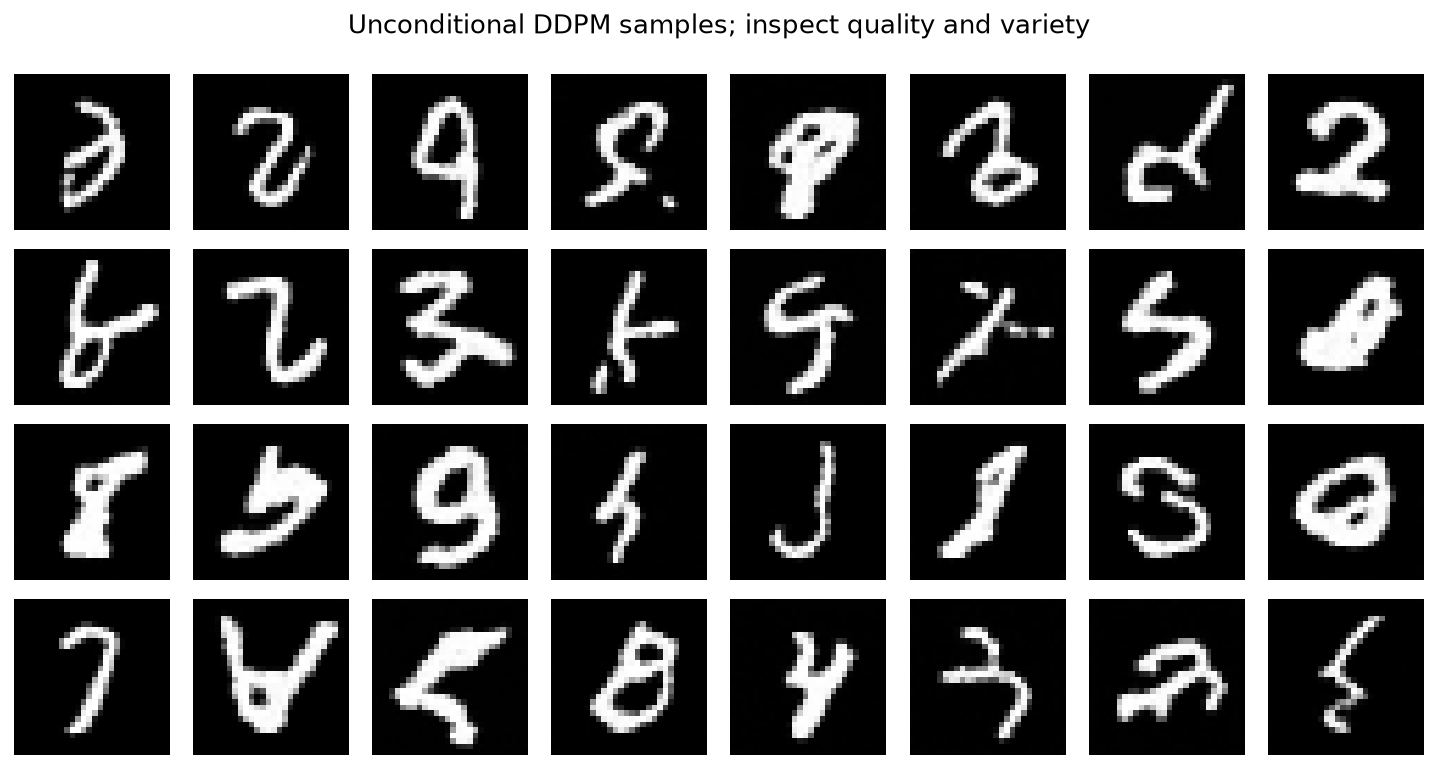

In [10]:
def x0_from_epsilon(x_t, t, epsilon):
    return (x_t - extract((1 - alpha_bars).sqrt(), t) * epsilon) / extract(alpha_bars.sqrt(), t)


@torch.no_grad()
def reverse_step(x_t, t, labels=None, guidance=0.0):
    eps_pred = ema_denoiser(x_t, t)
    if labels is not None:
        eps_pred = eps_pred + guidance * (ema_denoiser(x_t, t, labels) - eps_pred)
    x0_pred = x0_from_epsilon(x_t, t, eps_pred).clamp(-1, 1)
    mean = extract(posterior_coef_x0, t) * x0_pred + extract(posterior_coef_xt, t) * x_t
    noise = torch.randn_like(x_t)
    nonzero = (t > 0).float().unsqueeze(-1)
    return mean + nonzero * extract(posterior_variance.clamp(min=0).sqrt(), t) * noise


@torch.no_grad()
def sample_ddpm(count=32, initial=None, start_t=None, snapshots=False, labels=None, guidance=0.0):
    denoiser.eval()
    current = torch.randn(count, INPUT_DIM, device=device) if initial is None else initial.clone()
    start_t = T - 1 if start_t is None else start_t
    trace = {start_t + 1: current.detach().clone()}
    for step_t in range(start_t, -1, -1):
        t = torch.full((len(current),), step_t, dtype=torch.long, device=device)
        current = reverse_step(current, t, labels=labels, guidance=guidance)
        if snapshots and step_t in [75, 50, 25, 10, 0]:
            trace[step_t] = current.detach().clone()
    return current, trace


probe_t = torch.tensor([0, 10, 99], dtype=torch.long, device=device)
probe_x0 = x_test[:3]
probe_eps = torch.randn_like(probe_x0)
probe_xt = q_sample(probe_x0, probe_t, probe_eps)
oracle_x0_error = (x0_from_epsilon(probe_xt, probe_t, probe_eps) - probe_x0).abs().max().item()
assert oracle_x0_error < 5e-4, oracle_x0_error
assert posterior_variance[0].item() == 0.0
assert torch.isfinite(posterior_variance).all() and (posterior_variance >= 0).all()
print(f"Known-noise x0 reconstruction error: {oracle_x0_error:.2e}")

generated_digits, generation_trace = sample_ddpm(count=32, snapshots=True)
assert generated_digits.shape == (32, INPUT_DIM) and torch.isfinite(generated_digits).all()
image_grid(generated_digits, "Unconditional DDPM samples; inspect quality and variety")

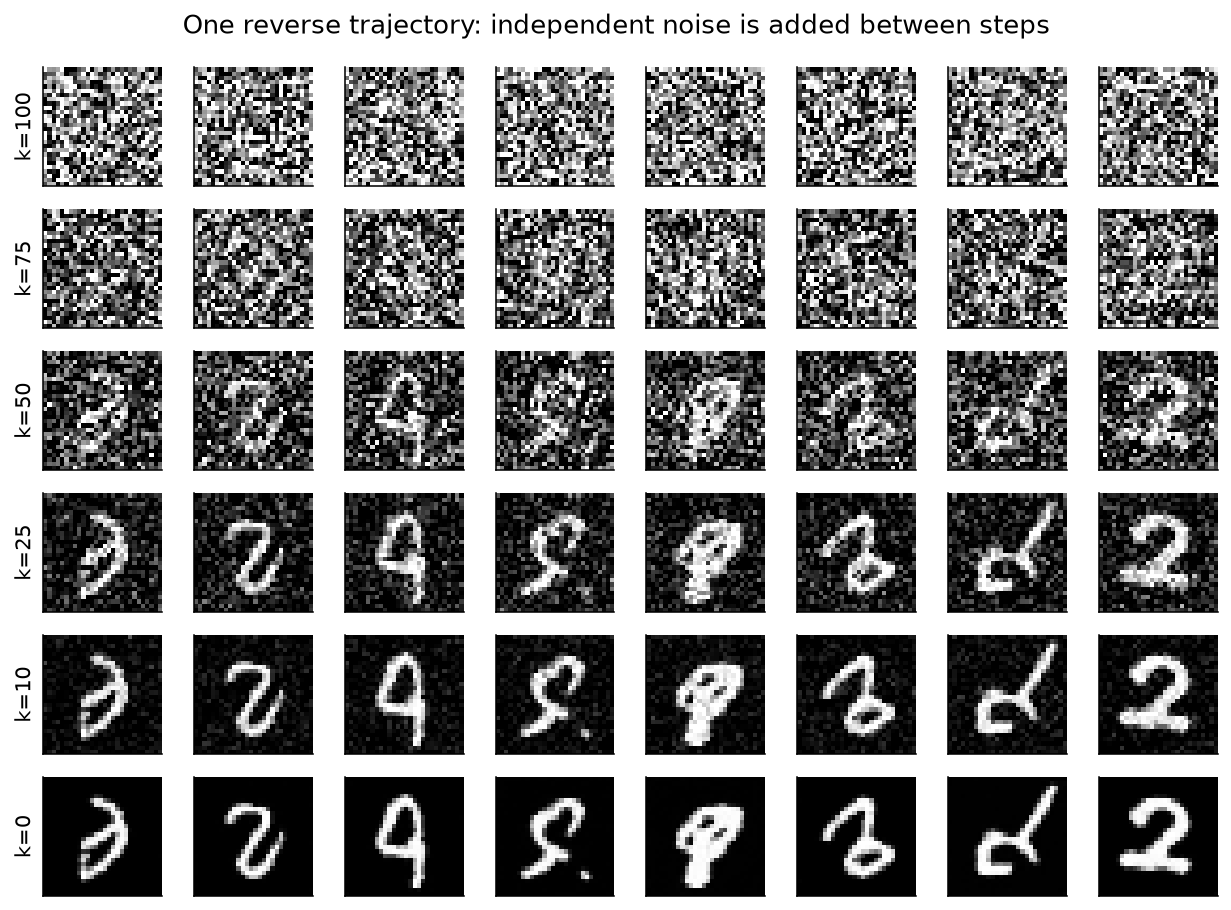

In [11]:
trace_steps = list(generation_trace)
fig, axes = plt.subplots(len(trace_steps), 8, figsize=(9, 1.1 * len(trace_steps)))
for row, k in enumerate(trace_steps):
    for col in range(8):
        axes[row, col].imshow(generation_trace[k][col].cpu().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(f"k={k}")
fig.suptitle("One reverse trajectory: independent noise is added between steps")
plt.tight_layout()
plt.show()

### Сравнение условий при одинаковом начальном шуме

- Каждому столбцу соответствует один начальный шум $x_T$.
- Строки: метки 0–9; условие передаётся на каждом обратном шаге.
- Сравнить $w=0,1,2$. Усиление условия не гарантирует устранение артефактов.
- Метка задаёт класс; гауссовский шум описывает разнообразие внутри него.

MNIST held-out probe accuracy: 0.907


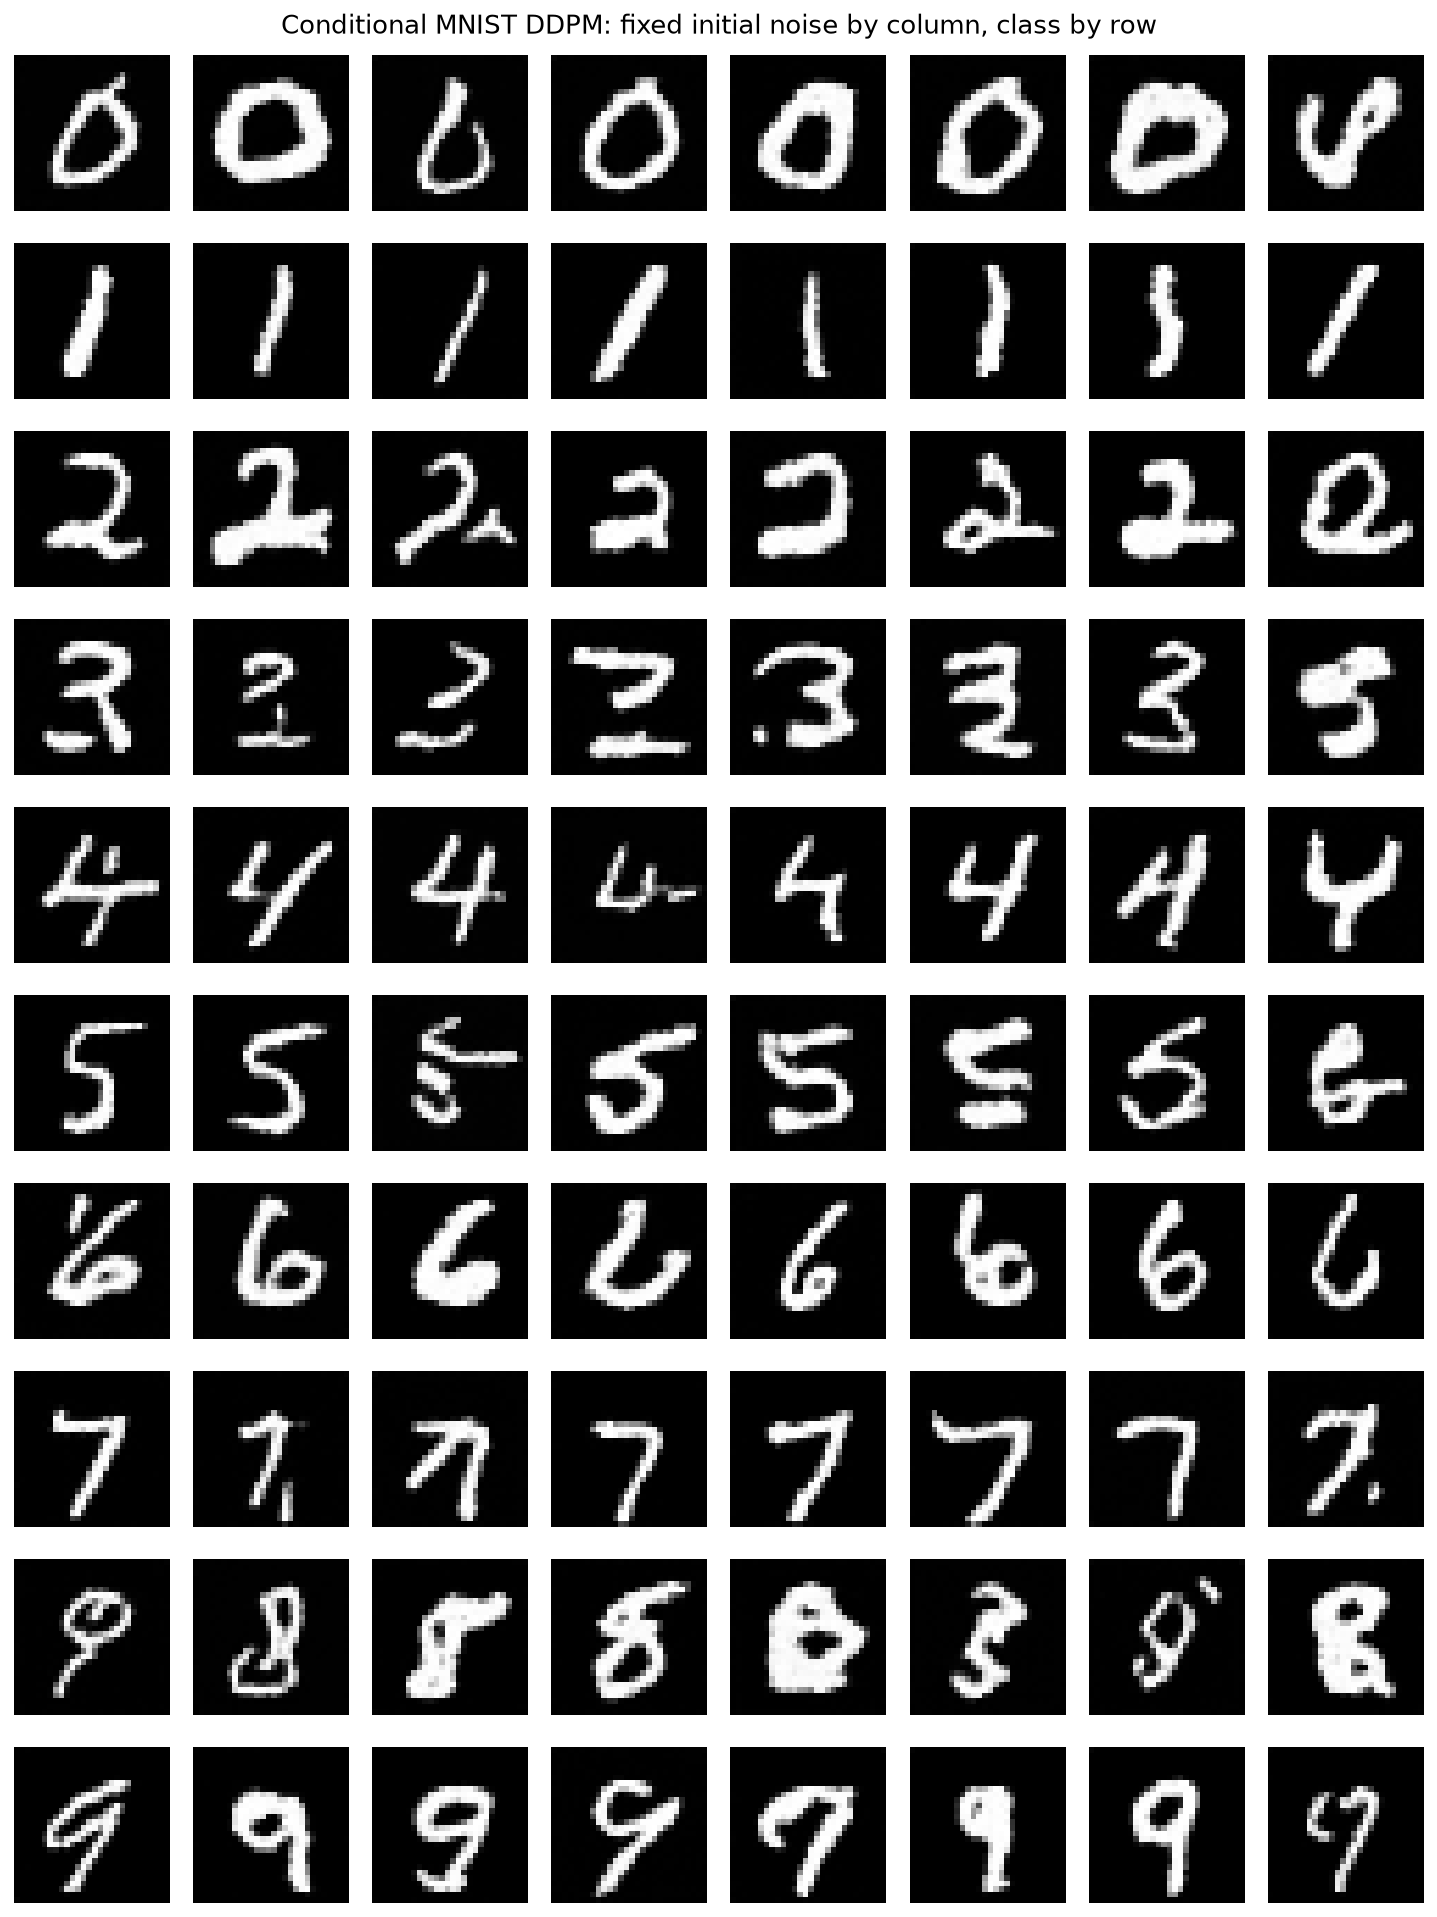

Conditional DDPM probe class agreement: 0.825
Class agreement does not measure diversity or guarantee sample quality.


In [12]:
from sklearn.linear_model import LogisticRegression
probe_classifier = LogisticRegression(max_iter=300, random_state=SEED)
probe_classifier.fit(digit_train_np, train_digit_labels)
print(f"MNIST held-out probe accuracy: {probe_classifier.score(digit_test_np, test_digit_labels):.3f}")
with torch.no_grad():
    torch.manual_seed(SEED + 100)
    fixed_start = torch.randn(8, INPUT_DIM, device=device)
    repeated_start = fixed_start.repeat(10, 1)
    requested = torch.arange(10, device=device).repeat_interleave(8)
    conditional_digits, _ = sample_ddpm(initial=repeated_start, labels=requested, guidance=1.5)
image_grid(conditional_digits, "Conditional MNIST DDPM: fixed initial noise by column, class by row", cols=8)
class_agreement = float((probe_classifier.predict(((conditional_digits.cpu().numpy()+1)/2)) == requested.cpu().numpy()).mean())
print(f"Conditional DDPM probe class agreement: {class_agreement:.3f}")
print("Class agreement does not measure diversity or guarantee sample quality.")

### Дополнительно: управление классом и guidance

- Короткий показ ведущего; основной самостоятельный опыт ниже — редактирование изображения.

| Параметр | Что меняет | Как сравнивать |
|---|---|---|
| TARGET_CLASS | Метку цифры для этого генеративного сэмплера | Зафиксировать SAMPLE_SEED и GUIDANCE_SCALE |
| SAMPLE_SEED | Начальный шум и случайные добавки обратной цепочки | Зафиксировать класс и guidance |
| GUIDANCE_SCALE | Силу условной поправки: 0 без условия, 1 обычное условие, >1 усиление | Зафиксировать класс и seed |

Это inference обученной сети: веса не изменяются. При w=0 выбранный класс игнорируется. Больший w не гарантирует более правильных/разнообразных цифр. TARGET_CLASS и SAMPLE_SEED этой ячейки **не управляют** следующим опытом SDEdit.
- Менять только `GUIDANCE_SCALE` при фиксированных классе и seed: 0, 1, 2. Начальный шум и случайные добавки цепочки воспроизводятся на одном устройстве.
- $w=0$ отключает условную поправку: выбранный класс не фиксируется. При $w>0$ условие управляет классом; случайность сохраняет вариативность результатов.

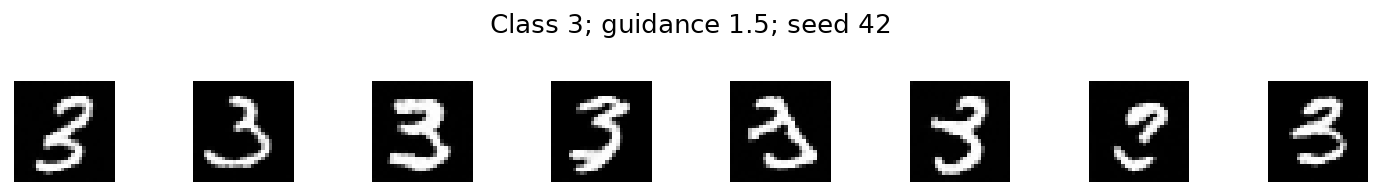

Inference only; no training performed.


In [13]:
#@title Optional: class and classifier-free guidance, inference only
TARGET_CLASS = 3 #@param {type:"slider", min:0, max:9, step:1}
GUIDANCE_SCALE = 1.5 #@param {type:"slider", min:0, max:3, step:0.5}
SAMPLE_SEED = 42 #@param {type:"integer"}

torch.manual_seed(SAMPLE_SEED)
live_initial = torch.randn(8, INPUT_DIM, device=device)
live_labels = torch.full((8,), TARGET_CLASS, dtype=torch.long, device=device)
live_digits, _ = sample_ddpm(initial=live_initial, labels=live_labels, guidance=GUIDANCE_SCALE)
image_grid(live_digits, f"Class {TARGET_CLASS}; guidance {GUIDANCE_SCALE}; seed {SAMPLE_SEED}", cols=8)
print("Inference only; no training performed.")

- **Анализ генерации:** распознаваемость цифр, повторения, смешение классов. Одна решётка не подтверждает покрытие распределения.
- **Дополнительный эксперимент:** заменить `eps_pred` на `torch.zeros_like(x_t)`; сравнить при одинаковом seed.

<details><summary>Пояснение</summary>

Расписание задаёт уровни шума; структуру данных представляют обученные веса.
</details>

Удаление случайной добавки или пропуск итераций меняет сэмплер; такая модификация сама по себе не реализует DDIM.

## 7. Image-to-image: редактирование через зашумление

- **Метод:** зашумление входа до уровня $k$ → обратный DDPM; учебный вариант [SDEdit](https://arxiv.org/abs/2108.01073).
- **Данные:** test-цифры с искусственной полосой; оригинал доступен для вычисления MSE.
- Зашумляется вся повреждённая картинка. Маска допустимых изменений отсутствует, поэтому обратная цепочка может изменить любой пиксель, включая неповреждённые штрихи.
- В этом опыте editing показан как исправление повреждения. В следующем разделе маска задаёт область пропуска и позволяет точно сохранить известные пиксели.
- **Практика 2, 10 минут:** сравнить `EDIT_LEVELS`, изменить средний уровень через `EDIT_K`, повторить только следующую ячейку. Переобучение не требуется; seed сбрасывается.
- **Как читать строки:** Original — чистый эталон; Damaged input — искусственное повреждение; Edit k=10 / EDIT_K / 70 — три уровня редактирования. Меняется только средний уровень; две крайние строки служат фиксированными ориентирами.
- **Слайдер EDIT_K:** уровень шума перед обратной цепочкой, не число шагов обучения. Чем больше k, тем больше свобода изменения и риск потерять детали входа. Веса не меняются; повторяется только inference.
- **Метрика:** pixel MSE по всему изображению к известному оригиналу, меньше — ближе по пикселям; это не универсальная оценка качества нового изображения.
- **Анализ:** сохранение штрихов и класса относительно степени изменения изображения.
- **Ограничение:** генеративный prior допускает изменение класса; точное условное восстановление не гарантируется.

Теория: [Редактирование с помощью диффузии](https://fpakhurov.com/ru/notes/generative-models/latent-diffusion/#editing-with-the-same-model), [DragGAN и DragDiffusion](https://fpakhurov.com/ru/notes/generative-models/drag-editing/).


- В данном контролируемом опыте известна метка test-изображения; она передаётся модели как дополнительное условие.
- Дополнительный опыт: сохранить зашумлённый вход, заменить правильную метку неверной; проверить изменение содержания. Условие полезно при корректной дополнительной информации.

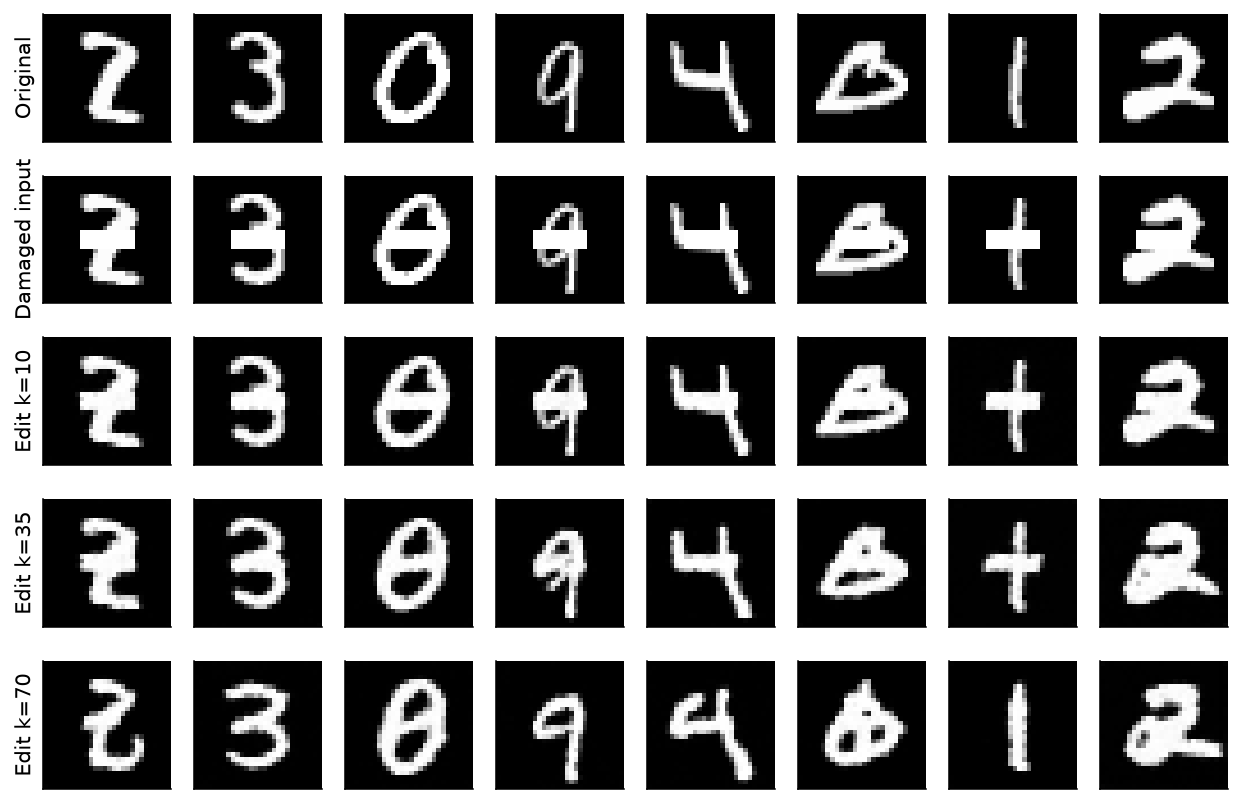

Pixel MSE to original in [-1, 1], damaged: 0.1488
Pixel MSE after editing: {10: 0.1435, 35: 0.1595, 70: 0.2312}


In [14]:
#@title Practice 2: change editing strength without retraining
EDIT_K = 35 #@param {type:"slider", min:15, max:65, step:5}

torch.manual_seed(SEED + 7)
clean_edit = x_test[:8].clone()
damaged_edit = clean_edit.reshape(-1, IMAGE_SIZE, IMAGE_SIZE).clone()
damaged_edit[:, 12:16, 8:20] = 1.0
damaged_edit = damaged_edit.reshape(-1, INPUT_DIM)
edit_noise = torch.randn_like(damaged_edit)
edit_results = {}
EDIT_LEVELS = [10, EDIT_K, 70]
for k in EDIT_LEVELS:
    torch.manual_seed(SEED + 8)
    t = torch.full((len(damaged_edit),), k - 1, dtype=torch.long, device=device)
    initial = q_sample(damaged_edit, t, edit_noise)
    edited, _ = sample_ddpm(initial=initial, start_t=k - 1, labels=y_test[:8], guidance=1.5)
    edit_results[k] = edited

rows = [("Original", clean_edit), ("Damaged input", damaged_edit)] + [(f"Edit k={k}", result) for k, result in edit_results.items()]
fig, axes = plt.subplots(len(rows), 8, figsize=(9, 6))
for row, (label, images) in enumerate(rows):
    for col in range(8):
        axes[row, col].imshow(images[col].cpu().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(label)
plt.tight_layout()
plt.show()
damaged_mse = F.mse_loss(damaged_edit, clean_edit).item()
edit_mse = {k: F.mse_loss(result, clean_edit).item() for k, result in edit_results.items()}
print("Pixel MSE to original in [-1, 1], damaged:", round(damaged_mse, 4))
print("Pixel MSE after editing:", {k: round(v, 4) for k, v in edit_mse.items()})

- **Масштаб MSE:** переход `[-1,1] → [0,1]` по формуле `(x+1)/2` уменьшает pixel MSE в 4 раза.
- MSE предсказания шума измеряет другую величину.
- Правдоподобное изменение класса может повышать MSE и нарушать требование сохранения содержания.

## 8. Дополнительно: заполнение пропусков

- **Маска:** $m=1$ на известных пикселях; $m=0$ в пропуске. В масштабе [-1,1] заполнение нулём выглядит серым (в первом семинаре [0,1] ноль был чёрным).
- Строки: Original → Gray fill → Inpainted. MSE оцениваем только в пропуске. Нулевая ошибка известных пикселей получается за счёт их принудительной подстановки; это не доказательство восстановления скрытого оригинала.
- **Проекция после обратного шага:**

$$x_{k-1}\leftarrow m\odot x_{k-1}^{known}+(1-m)\odot x_{k-1}^{generated}.$$

- Известная область зашумляется до соответствующего уровня; на финале возвращаются исходные пиксели.
- Используется та же обученная DDPM. Маску обрабатывает сэмплер через подстановку известных пикселей. U-Net получает $x_k$, $k$, $y$ и обучена предсказывать шум.
- **Метрики:** сохранение известных пикселей; MSE только внутри пропуска относительно серого заполнения.
- **Ограничение:** эвристика; не точный conditional posterior и не полная схема RePaint.

| Свойство | Editing в разделе 7 | Inpainting в разделе 8 |
|---|---|---|
| Вход | Повреждённая цифра и метка класса | Известные пиксели, маска и метка класса |
| Сохранение входа | Приблизительное, зависит от уровня шума | Известные пиксели точно возвращаются на финале |
| Что может измениться в результате | Любой пиксель | Только область пропуска |
| MSE | По всему изображению | Только в пропуске |

В разделах используются разные test-изображения, повреждения и области расчёта MSE. Числа из двух разделов не дают прямого сравнения качества методов. Внутри каждого опыта сравнивайте результат с его собственным повреждённым входом.

Теория: [Score matching](https://fpakhurov.com/ru/notes/generative-models/score-matching/), [RePaint](https://arxiv.org/abs/2201.09865).

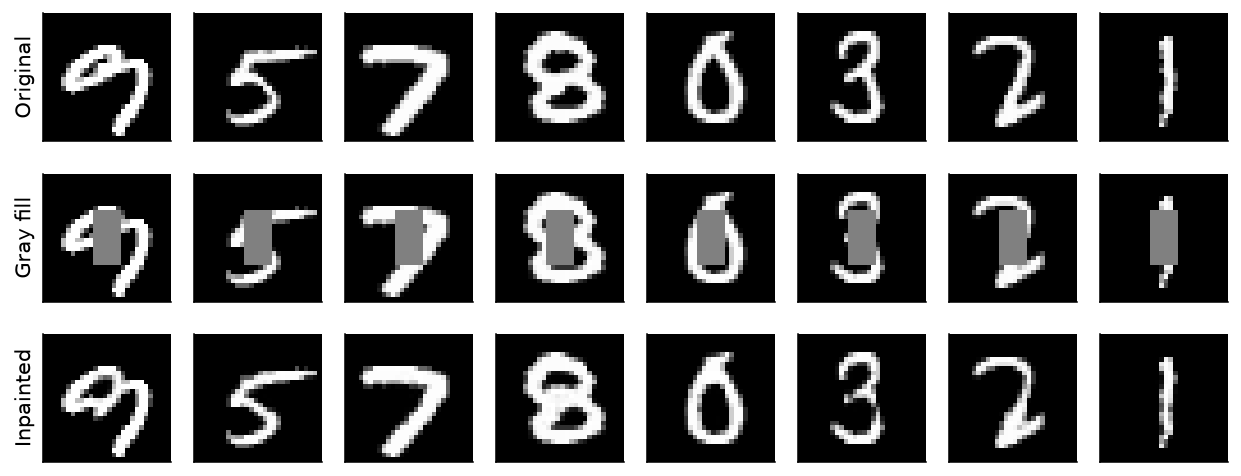

Known-pixel max error: 0.00e+00
Missing-pixel MSE, gray fill: 0.8028; inpainting: 0.4432


In [15]:
@torch.no_grad()
def inpaint(known_image, known_mask, labels=None):
    current = torch.randn_like(known_image)
    known_noise = torch.randn_like(known_image)
    top_t = torch.full((len(current),), T - 1, dtype=torch.long, device=device)
    current = known_mask * q_sample(known_image, top_t, known_noise) + (1 - known_mask) * current
    for step_t in range(T - 1, -1, -1):
        t = torch.full((len(current),), step_t, dtype=torch.long, device=device)
        current = reverse_step(current, t, labels=labels, guidance=1.5)
        if step_t > 0:
            previous_t = torch.full((len(current),), step_t - 1, dtype=torch.long, device=device)
            known_at_level = q_sample(known_image, previous_t, known_noise)
        else:
            known_at_level = known_image
        current = known_mask * known_at_level + (1 - known_mask) * current
    return current

inpaint_original = x_test[8:16].clone()
known_mask = torch.ones_like(inpaint_original).reshape(-1, IMAGE_SIZE, IMAGE_SIZE)
known_mask[:, 8:20, 11:17] = 0.0
known_mask = known_mask.reshape(-1, INPUT_DIM)
inpaint_input = known_mask * inpaint_original
inpaint_result = inpaint(inpaint_original, known_mask, labels=y_test[8:16])
known_pixel_error = ((inpaint_result - inpaint_original) * known_mask).abs().max().item()
assert known_pixel_error < 1e-6, known_pixel_error
missing_mask = 1 - known_mask
inpaint_missing_mse = (((inpaint_result - inpaint_original).square() * missing_mask).sum() / missing_mask.sum()).item()
gray_fill_missing_mse = (((inpaint_input - inpaint_original).square() * missing_mask).sum() / missing_mask.sum()).item()

fig, axes = plt.subplots(3, 8, figsize=(9, 3.7))
for row, (label, images) in enumerate([("Original", inpaint_original), ("Gray fill", inpaint_input), ("Inpainted", inpaint_result)]):
    for col in range(8):
        axes[row, col].imshow(images[col].cpu().reshape(IMAGE_SIZE, IMAGE_SIZE), cmap="gray", vmin=-1, vmax=1)
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
        if col == 0:
            axes[row, col].set_ylabel(label)
plt.tight_layout()
plt.show()
print(f"Known-pixel max error: {known_pixel_error:.2e}")
print(f"Missing-pixel MSE, gray fill: {gray_fill_missing_mse:.4f}; inpainting: {inpaint_missing_mse:.4f}")

- **Дополнительный эксперимент:** увеличить пропуск; сравнить два результата с разными seeds.
- **Неоднозначность:** разные цифры могут совпадать на известных пикселях; правдоподобие не подтверждает восстановление оригинала.

## 9. Сравнение моделей

| Модель | Обучение | Генерация | Проверка |
|---|---|---|---|
| VAE | Восстановление + KL | Prior → decoder | Качество; согласованность prior/posterior |
| GAN | Состязательная оптимизация | Шум → генератор | Качество; разнообразие; коллапс мод |
| Поток | Точное правдоподобие | Обратимое преобразование | Test NLL; logdet; обратимость |
| Диффузия | Предсказание шума | Последовательность переходов | Качество; разнообразие; стоимость генерации |

- Точность вычисления плотности потока относится к модели, а не к истинному распределению.
- DDPM использует стохастический приближённый обратный процесс; обычный сэмплер не является обратимым потоком.
- Выбор downstream-метода зависит от условий: класс, парные изображения, непарные домены, частичные наблюдения.

**Контрольные вопросы:** назначение logdet; роль сети при известном начальном $x_T$; неоднозначность восстановления.

<details><summary>Ответы</summary>

- Logdet учитывает изменение объёма.
- $x_T$ известен, но исходная чистая цифра не задана. Сеть задаёт обратные переходы, согласованные с данными.
- Наблюдаемый фрагмент допускает несколько продолжений; одно изображение не устанавливает истинный оригинал.
</details>


| Семейство | Ограничение базовой модели | Новое решение | Условный вариант |
|---|---|---|---|
| AE | Не задано распределение кодов | Реконструкция через bottleneck | Кодирование входа |
| VAE (2013) | Неудобный точный posterior | ELBO и обучаемый $q(z\mid x)$ | $p(x\mid z,y)$, $q(z\mid x,y)$ |
| GAN (2014) | Простое пиксельное likelihood | Состязательная целевая функция | $G(z,y)$ и $D(x,y)$ |
| NICE/RealNVP (2014–2016) | Приближённая плотность/inference | Обратимость и точный logdet | $p(x\mid y)$ |
| DDPM (2020) | Сложность прямого построения изображения | Последовательное удаление шума | Метка класса и CFG |

Семейства развивались параллельно; сравниваются ограничения и вычислительные компромиссы. Loss разных семейств численно не сопоставляется.

In [16]:
SEMINAR_RESULTS = {
    "quick_mode": QUICK,
    "device": str(device),
    "flow_steps": FLOW_STEPS,
    "ddpm_steps": DDPM_STEPS,
    "conditional_class_agreement": class_agreement,
    "conditional_flow_marginal_nll": conditional_flow_marginal_nll,
    "gaussian_test_nll": gaussian_nll,
    "flow_test_nll": flow_nll,
    "flow_roundtrip_max_error": roundtrip_error,
    "flow_jacobian_logdet_error": jacobian_logdet_error,
    "ddpm_test_noise_mse": test_noise_mse,
    "ddpm_zero_predictor_mse": zero_noise_mse,
    "oracle_x0_max_error": oracle_x0_error,
    "damaged_edit_mse": damaged_mse,
    "edit_mse_by_start_k": edit_mse,
    "inpaint_known_pixel_max_error": known_pixel_error,
    "inpaint_missing_mse": inpaint_missing_mse,
    "gray_fill_missing_mse": gray_fill_missing_mse,
    "flow_seconds": flow_seconds,
    "ddpm_seconds": ddpm_seconds,
}
print(SEMINAR_RESULTS)

{'quick_mode': False, 'device': 'mps', 'flow_steps': 1600, 'ddpm_steps': 6000, 'conditional_class_agreement': 0.825, 'conditional_flow_marginal_nll': 1.5373486280441284, 'gaussian_test_nll': 2.718989372253418, 'flow_test_nll': 1.5947524309158325, 'flow_roundtrip_max_error': 7.152557373046875e-07, 'flow_jacobian_logdet_error': 1.6689300537109375e-06, 'ddpm_test_noise_mse': 0.04216247797012329, 'ddpm_zero_predictor_mse': 0.9989173412322998, 'oracle_x0_max_error': 0.000205308198928833, 'damaged_edit_mse': 0.1487535536289215, 'edit_mse_by_start_k': {10: 0.14349791407585144, 35: 0.15946519374847412, 70: 0.23120947182178497}, 'inpaint_known_pixel_max_error': 0.0, 'inpaint_missing_mse': 0.4431730806827545, 'gray_fill_missing_mse': 0.802769660949707, 'flow_seconds': 5.483459332957864, 'ddpm_seconds': 374.98830316599924}


## Первоисточники и материалы курса

- [HSE-LAMBDA: Deep Generative Models](https://github.com/HSE-LAMBDA/DeepGenerativeModels/tree/spring-2025-long).
- [Real NVP](https://arxiv.org/abs/1605.08803): обратимые coupling-преобразования.
- [DDPM](https://arxiv.org/abs/2006.11239): прямой процесс, posterior, обучение.
- [SDEdit](https://arxiv.org/abs/2108.01073): редактирование через шум.
- [RePaint](https://arxiv.org/abs/2201.09865): диффузионный inpainting.
- [MNIST](https://pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html): источник рукописных цифр.

Реализации самостоятельные; тематические ссылки на подробную теорию приведены в соответствующих разделах.